In [4]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from scipy.signal import resample
from sklearn.preprocessing import StandardScaler

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
# Set the base directory
DATA_DIR = '/content/drive/MyDrive/Colab_Notebooks/NextBeat_za_matura/'

# --- 1. Load and prepare the Demographics ---
# Use os.path.join to attach the filename automatically
info_path = os.path.join(DATA_DIR, 'information.csv')
info_df = pd.read_csv(info_path)

info_df['ID'] = info_df['ID'].astype(str).str.zfill(3)
info_df['Gender'] = info_df['Gender'].map({'Male': 1, 'Female': 0})
demo_cols = ['Age', 'Gender', 'Height/cm', 'Weight/kg', 'SBP/mmHg', 'DBP/mmHg']

scaler = StandardScaler()
info_df[demo_cols] = scaler.fit_transform(info_df[demo_cols])

# Create the dictionary
demo_dict = info_df.set_index('ID')[demo_cols].to_dict('index')

# --- 2. Load the Signals ---
ORIGINAL_FS = 250
TARGET_FS = 100
WINDOW_SIZE = 1000
STEP_SIZE = 500

CSV_DIR = os.path.join(DATA_DIR, 'train_test_data')
csv_files = sorted(glob.glob(os.path.join(CSV_DIR, '*_*.csv'))) # Use os.path.join here too. It will grab 001_1.csv, 002_1.csv, etc.

print(f"Found {len(csv_files)} signal files.")

Found 90 signal files.


In [9]:
# --- 3. Get the input features (X_ppg and X_demo) and target labels (Y_ecg) ---
X_ppg = []
X_demo = []
Y_ecg = []

for f in csv_files:
    try:
        # Extract ID from filename (e.g., '/content/001_2.csv' -> '001')
        filename = os.path.basename(f)
        patient_id = filename.split('_')[0]
        # Get the demographic vector for this patient
        if patient_id not in demo_dict:
            continue
        patient_demo = list(demo_dict[patient_id].values())


        # Read the CSV
        df = pd.read_csv(f)

        # The 5th column contains text/formulas, only need cols 2nd (ECG_I_mV) and 4th (PPG_IR_Filtered) - this was decided after downloading the dataset and viewing some of the csv files
        # Convert to numeric, but keep them in a combined DataFrame to drop NaNs together
        df['PPG'] = pd.to_numeric(df['PPG_IR_Filtered'], errors='coerce')
        df['ECG'] = pd.to_numeric(df['ECG_I_mV'], errors='coerce')
        # Drop rows where EITHER is missing to keep them perfectly aligned
        clean_df = df.dropna(subset=['PPG', 'ECG'])

        ppg = clean_df['PPG'].values
        ecg = clean_df['ECG'].values

        # Ensure they are the same length
        min_len = min(len(ppg), len(ecg))
        ppg = ppg[:min_len]
        ecg = ecg[:min_len]

        # DOWNSAMPLE from 250Hz to 100Hz
        new_len = int(len(ppg) * (TARGET_FS / ORIGINAL_FS))
        ppg_resampled = resample(ppg, new_len)
        ecg_resampled = resample(ecg, new_len)

        if len(ppg_resampled) < WINDOW_SIZE:
            continue

        # Slice into windows
        for i in range(0, len(ppg_resampled) - WINDOW_SIZE, STEP_SIZE):
            ppg_window = ppg_resampled[i:i+WINDOW_SIZE]
            ecg_window = ecg_resampled[i:i+WINDOW_SIZE]

            # Normalize to [0, 1] for the neural network
            ppg_min, ppg_max = np.min(ppg_window), np.max(ppg_window)
            ecg_min, ecg_max = np.min(ecg_window), np.max(ecg_window)

            if ppg_max > ppg_min and ecg_max > ecg_min:
                ppg_norm = (ppg_window - ppg_min) / (ppg_max - ppg_min)
                ecg_norm = (ecg_window - ecg_min) / (ecg_max - ecg_min)

                X_ppg.append(ppg_norm)
                Y_ecg.append(ecg_norm)
                X_demo.append(patient_demo)

    except Exception as e:
        print(f"Skipping {f}: {e}")

X_ppg = np.array(X_ppg).reshape(-1, WINDOW_SIZE, 1)
Y_ecg = np.array(Y_ecg).reshape(-1, WINDOW_SIZE, 1)
X_demo = np.array(X_demo)

print(f"Total windows generated: {X_ppg.shape[0]}")

Total windows generated: 3060


In [10]:
# --- 4. Split into 80% train, 20% test ---
X_ppg_train, X_ppg_test, X_demo_train, X_demo_test, Y_ecg_train, Y_ecg_test = train_test_split(
    X_ppg, X_demo, Y_ecg, test_size=0.2, random_state=42
)

In [11]:
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, UpSampling1D, Concatenate, Dense, RepeatVector, Cropping1D, ZeroPadding1D
from tensorflow.keras.models import Model

In [12]:
# --- 5. Generative model, with two inputs (second demographic input is to correct bias and get more personalized results) ---
def build_conditioned_model(window_size):
    # --- INPUT 1: PPG ---
    ppg_inputs = Input(shape=(window_size, 1), name='ppg_input')

    # --- INPUT 2: Demographics ---
    demo_inputs = Input(shape=(6,), name='demo_input')
    d = Dense(32, activation='relu')(demo_inputs)
    d = RepeatVector(62)(d) # Matches the bottleneck size exactly

    # --- ENCODER ---
    c1 = Conv1D(32, kernel_size=7, activation='relu', padding='same')(ppg_inputs) # 1000
    p1 = MaxPooling1D(pool_size=4)(c1) # 250

    c2 = Conv1D(64, kernel_size=7, activation='relu', padding='same')(p1) # 250
    p2 = MaxPooling1D(pool_size=4)(c2) # 62

    c3 = Conv1D(128, kernel_size=7, activation='relu', padding='same')(p2) # 62

    # --- MERGE DEMOGRAPHICS WITH PPG BOTTLENECK ---
    merged = Concatenate()([c3, d]) # 62 and 62

    # --- DECODER ---
    u1 = UpSampling1D(size=4)(merged) # 62 * 4 = 248

    # Crop c2 from 250 down to 248 so they match perfectly
    c2_cropped = Cropping1D(cropping=(0, 2))(c2)
    c4 = Concatenate()([u1, c2_cropped])
    c4 = Conv1D(64, kernel_size=7, activation='relu', padding='same')(c4)

    u2 = UpSampling1D(size=4)(c4) # 248 * 4 = 992

    # Crop c1 from 1000 down to 992 so they match perfectly
    c1_cropped = Cropping1D(cropping=(0, 8))(c1)
    c5 = Concatenate()([u2, c1_cropped])
    c5 = Conv1D(32, kernel_size=7, activation='relu', padding='same')(c5)

    outputs = Conv1D(1, kernel_size=7, activation='sigmoid', padding='same')(c5)

    # Pad the end by 8 so the final output is exactly 1000 again
    outputs_padded = ZeroPadding1D(padding=(0, 8))(outputs)

    model = Model(inputs=[ppg_inputs, demo_inputs], outputs=outputs_padded)
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

model = build_conditioned_model(WINDOW_SIZE)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ppg_input           │ (None, 1000, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 1000, 32)  │        256 │ ppg_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 250, 32)   │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 250, 64)   │     14,400 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ demo_input          │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 62, 64)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        224 │ demo_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 62, 128)   │     57,472 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 62, 32)    │          0 │ dense[0][0]       │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 62, 160)   │          0 │ conv1d_2[0][0],   │
│ (Concatenate)       │                   │            │ repeat_vector[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling1d       │ (None, 248, 160)  │          0 │ concatenate[0][0] │
│ (UpSampling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cropping1d          │ (None, 248, 64)   │          0 │ conv1d_1[0][0]    │
│ (Cropping1D)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 248, 224)  │          0 │ up_sampling1d[0]… │
│ (Concatenate)       │                   │            │ cropping1d[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 248, 64)   │    100,416 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling1d_1     │ (None, 992, 64)   │          0 │ conv1d_3[0][0]    │
│ (UpSampling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cropping1d_1        │ (None, 992, 32)   │          0 │ conv1d[0][0]      │
│ (Cropping1D)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 992, 96)   │          0 │ up_sampling1d_1[… │
│ (Concatenate)       │                   │            │ cropping1d_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 992, 32)   │     21,536 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 992, 1)    │        225 │ conv1d_4[0][0]  

 Total params: 194,529 (759.88 KB)

 Trainable params: 194,529 (759.88 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# --- 6. Train loop and fit model ---
# Stop training early if the model stops improving
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    [X_ppg_train, X_demo_train], # Pass both inputs here
    Y_ecg_train,
    validation_data=([X_ppg_test, X_demo_test], Y_ecg_test),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 24s 277ms/step - loss: 0.0292 - mae: 0.1316 - val_loss: 0.0250 - val_mae: 0.1195
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 22s 286ms/step - loss: 0.0236 - mae: 0.1153 - val_loss: 0.0226 - val_mae: 0.1123
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 40s 272ms/step - loss: 0.0218 - mae: 0.1104 - val_loss: 0.0212 - val_mae: 0.1076
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 21s 277ms/step - loss: 0.0202 - mae: 0.1054 - val_loss: 0.0193 - val_mae: 0.1030
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 44s 322ms/step - loss: 0.0186 - mae: 0.1003 - val_loss: 0.0185 - val_mae: 0.1005
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 25s 330ms/step - loss: 0.0178 - mae: 0.0978 - val_loss: 0.0184 - val_mae: 0.1007
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 26s 337ms/step - loss: 0.0176 - mae: 0.0970 - val_loss: 0.0174 - val_mae: 0.0965
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 26s 336ms/step - loss: 0.0172 - mae: 0.0957 - val_loss: 0.0170 - val_mae: 0.0947
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 22s 284ms/

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step


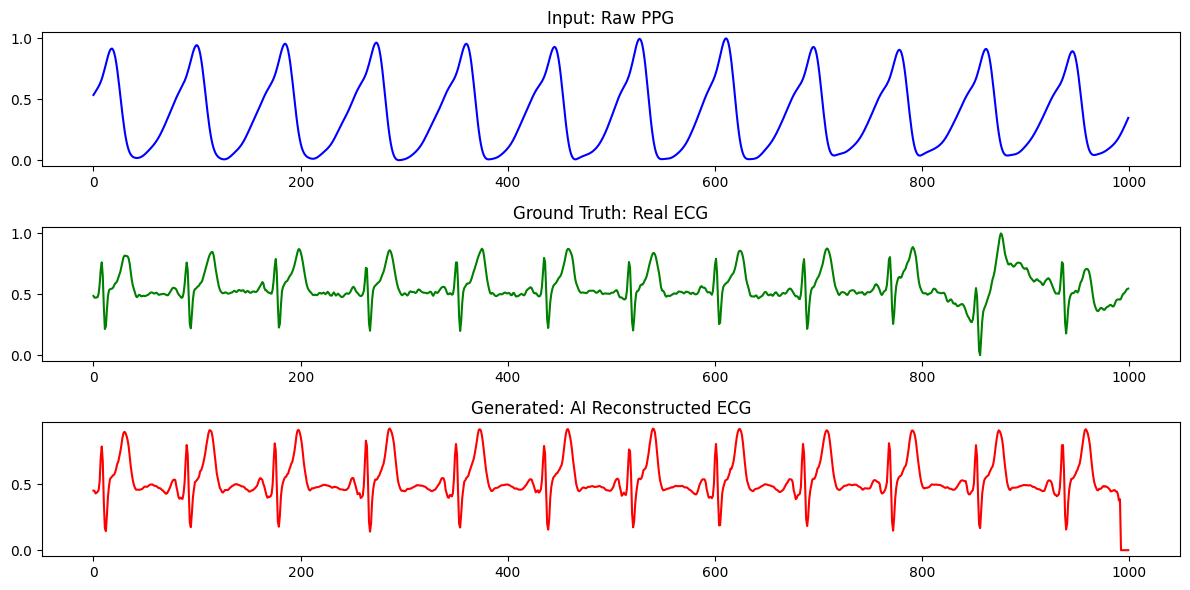

In [14]:
# --- 7. Visualize results ---
# Pick random test sample
idx = np.random.randint(0, len(X_ppg_test))
ppg_sample = X_ppg_test[idx]
demo_sample = X_demo_test[idx]
real_ecg = Y_ecg_test[idx]

# Predict needs BOTH inputs, and they need a batch dimension (1, ...)
pred_ecg = model.predict([np.expand_dims(ppg_sample, axis=0), np.expand_dims(demo_sample, axis=0)])[0]

# Plot them
plt.figure(figsize=(12, 6))

plt.subplot(3, 1, 1)
plt.plot(ppg_sample, color='blue')
plt.title('Input: Raw PPG')

plt.subplot(3, 1, 2)
plt.plot(real_ecg, color='green')
plt.title('Ground Truth: Real ECG')

plt.subplot(3, 1, 3)
plt.plot(pred_ecg, color='red')
plt.title('Generated: AI Reconstructed ECG')

plt.tight_layout()
plt.show()

In [15]:
# --- 8. Convert the model to TFLite, to save it to the Pi ---
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT] # Compress it
tflite_model = converter.convert()

with open('ppg_to_ecg_model.tflite', 'wb') as f:
    f.write(tflite_model)

print("TFLite model saved!")

Saved artifact at '/tmp/tmpbjx6mfxr'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 1000, 1), dtype=tf.float32, name='ppg_input'), TensorSpec(shape=(None, 6), dtype=tf.float32, name='demo_input')]
Output Type:
  TensorSpec(shape=(None, 1000, 1), dtype=tf.float32, name=None)
Captures:
  137892497770064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137892497770832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137892497769872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137892497770640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137892512956240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137892497770448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137892497769680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137892497771024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137892497769488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1378924977719